## Hydrodynamic model of the Southern North Sea

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch
import optuna
import ast


# dataset helper
from helper import get_wl_point_obs, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Data Loading

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

# load simulation
ds = dfs.read(time=slice("2022-01-01", "2023-10-30"))
valid_nodes = ~np.isnan(ds["Surface elevation"].values).any(axis=0)
H, U, V = [
    torch.tensor(ds[var].values[:, valid_nodes], dtype=torch.float32)
    for var in ("Surface elevation", "U velocity", "V velocity")
]
print("Simulation data loaded successfully.")

# load observations
high_fidelity = {"Dover", "ZeebruggeWielingendok", "NWA", "K141"}
stations = [obs for obs in get_wl_point_obs() if obs.name in high_fidelity]
measurements = torch.tensor(
    extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr),
    dtype=torch.float32,
)
print("Observation data loaded successfully.\n")

# print array shapes
for name, x in {"H": H, "U": U, "V": V, "Measurements": measurements}.items():
    print(f"{name} shape:", x.shape, ".\tNumber of NaNs:", torch.isnan(x).sum().item())

del dfs

Simulation data loaded successfully.
Observation data loaded successfully.

H shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
U shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
V shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
Measurements shape: torch.Size([32064, 4]) .	Number of NaNs: 25037


## Hyperparameters

In [4]:
##########################################################################################################
################## FIXED HYPERPARAMETERS FOR TUNING RUNS #################################################
##########################################################################################################
ERRORS = []

# DataManager
LAGS = 48               # number of past time steps to use as input for the model
TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing
COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)
MASKING_TYPE = "mask_data"  # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)
BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training

##########################################################################################################
################## GRID OF HYPERPARAMETERS TO TUNE #######################################################
##########################################################################################################

# Architecture
TRANSFORMER_TYPE = ["transformer", "transformer_hidden_mask", "transformer_attn_mask", "transformer_learned_mask"]  
DOUBLE_CHANNEL = [True, False]                  # whether to use double channel input (H,U,V) or single channel (H only)
MAX_ENCODER_DEPTH = 4                           # number of encoder layers
HIDDEN_SIZE = [16,32,48,64]                        # hidden size for encoder and decoder layers
N_HEADS = 4                                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = [32,48,64,128]                   # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = ["cnn","mlp"]                         # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = ["64", "64,96", "96"]    # sampled as strings; parsed to int list in create_model
MAX_DROPOUT = 0.2                               # dropout rate for encoder and decoder layers

N_OPTUNA_TRIALS = 100  # number of Optuna trials to run for hyperparameter tuning

print("Total number of hyperparameter combinations to explore:", len(TRANSFORMER_TYPE) * len(DOUBLE_CHANNEL) * len(HIDDEN_SIZE) * len(DIM_FEEDFORWARD) * len(DECODER) * len(DECODER_HIDDEN_SIZES) * 4 * 3)

Total number of hyperparameter combinations to explore: 9216


## DataManager

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]


Data shapes after preparation:
Train:	 torch.Size([25651, 48, 4]) -> torch.Size([25651, 120])
Val:	 torch.Size([3206, 48, 4]) -> torch.Size([3206, 120])
Test:	 torch.Size([3207, 48, 4]) -> torch.Size([3207, 120])


## Training

In [6]:
# create model from Optuna trial
def create_model(trial):
    return dict(
        encoder              = trial.suggest_categorical('encoder', TRANSFORMER_TYPE),
        double_channels      = trial.suggest_categorical('double_channels', DOUBLE_CHANNEL),
        encoder_depth        = trial.suggest_int('encoder_depth', 1, MAX_ENCODER_DEPTH),
        n_heads              = N_HEADS,
        dim_feedforward      = trial.suggest_categorical('dim_feedforward', DIM_FEEDFORWARD),
        hidden_size          = trial.suggest_categorical('hidden_size', HIDDEN_SIZE),
        input_length         = LAGS,
        decoder              = trial.suggest_categorical('decoder', DECODER),
        decoder_hidden_sizes = [int(x) for x in trial.suggest_categorical('decoder_hidden_sizes', DECODER_HIDDEN_SIZES).split(',')],
        dropout              = trial.suggest_float('dropout', 0.0, MAX_DROPOUT, step=0.1),
        input_size           = nn_input_shape,
        output_size          = nn_output_shape,
    )

# objective function for Optuna to minimize (validation loss)
def objective(trial):

    # create model from trial hyperparameters
    model_args = create_model(trial)
    mshred = mSHRED(args=model_args).to(device)
    
    # fit model and get training and validation losses
    _ , valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=False,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, masking_type=MASKING_TYPE,
    )

    # Evaluating model on test set using the best model from training (early stopping)
    test_error = evaluate_model(
        evaluate, mshred, train_dataset, val_dataset, test_dataset,
        model=f"(mSHRED)", type=f"{model_args}", masking_type=MASKING_TYPE
    )

    # Logging errors and disply the last row
    ERRORS.append(test_error)                   # log test error for current trial
    dataframe_errors = pd.DataFrame(ERRORS)     # create dataframe from logged errors
    #display(dataframe_errors.tail(1))          # display last row of errors dataframe
    dataframe_errors.to_csv('dataframe_errors_optuna.csv', index=False)     # save errors to csv after each trial

    # return validation error for Optuna to minimize
    return float(test_error["val-mse"])

In [ ]:
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=N_OPTUNA_TRIALS)

[I 2026-05-10 20:41:24,080] A new study created in memory with name: no-name-c2c5ed4a-e9f9-43a6-992a-e33cdd20af79


[I 2026-05-10 20:44:56,547] Trial 0 finished with value: 0.004277291672719097 and parameters: {'encoder': 'transformer_attn_mask', 'double_channels': False, 'encoder_depth': 1, 'dim_feedforward': 64, 'hidden_size': 64, 'decoder': 'cnn', 'decoder_hidden_sizes': '96', 'dropout': 0.0}. Best is trial 0 with value: 0.004277291672719097.
[I 2026-05-10 21:12:14,593] Trial 1 finished with value: 0.00413233823632718 and parameters: {'encoder': 'transformer', 'double_channels': False, 'encoder_depth': 4, 'dim_feedforward': 48, 'hidden_size': 48, 'decoder': 'mlp', 'decoder_hidden_sizes': '96', 'dropout': 0.1}. Best is trial 1 with value: 0.00413233823632718.
[I 2026-05-10 21:33:52,632] Trial 2 finished with value: 0.004158779725906481 and parameters: {'encoder': 'transformer_attn_mask', 'double_channels': False, 'encoder_depth': 2, 'dim_feedforward': 32, 'hidden_size': 16, 'decoder': 'cnn', 'decoder_hidden_sizes': '96', 'dropout': 0.1}. Best is trial 1 with value: 0.00413233823632718.
[I 2026-05-

## Results

In [6]:
LAGS = 2448
dataframe_errors = pd.read_csv(f"results_df/notebook5/dataframe_errors_optuna_{LAGS}.csv")
dataframe_errors_baseline = pd.read_csv(f"results_df/notebook5/baselines_{LAGS}.csv")
dataframe_errors = dataframe_errors.sort_values(by="val-mre")
dataframe_errors_baseline = dataframe_errors_baseline.sort_values(by="val-mre")

# Parse the 'type' column string into a dict and expand into columns
type_df = dataframe_errors['type'].apply(lambda x: ast.literal_eval(x)).apply(pd.Series)
# Remove columns with the same value across all rows
type_df = type_df.drop(columns=['input_size', 'output_size', 'input_length', 'n_heads'])
# Add the val-mre column
type_df['val-mre'] = dataframe_errors['val-mre'].values

# Keep only 2 cols for baseline dataframe
dataframe_errors_baseline = dataframe_errors_baseline[["model", "val-mre"]]
# Make the average val-mre of the tuning runs the last row of the baseline dataframe for easier comparison in the plot
average_test_mre_baseline = dataframe_errors_baseline["val-mre"].mean()
max_test_mre = dataframe_errors_baseline["val-mre"].max()
min_test_mre = dataframe_errors_baseline["val-mre"].min()

print("Dataframe with hyperparameters ordered by validation MRE:")
display(type_df.head(10))

print("Baseline models val-mre average: {:.3f}%".format(average_test_mre_baseline*100))
print("Baseline models val-mre range: [{:.3f}%, {:.3f}%]".format(min_test_mre*100, max_test_mre*100))

Dataframe with hyperparameters ordered by validation MRE:


,encoder,double_channels,encoder_depth,dim_feedforward,hidden_size,decoder,decoder_hidden_sizes,dropout,val-mre
176,transformer_learned_mask,False,4,48,32,cnn,"[64, 96]",0.1,0.125566
124,transformer,False,4,48,48,mlp,[96],0.1,0.125747
174,transformer_learned_mask,False,4,48,32,cnn,"[64, 96]",0.1,0.125771
162,transformer_attn_mask,False,4,48,32,mlp,"[64, 96]",0.1,0.125868
164,transformer_attn_mask,False,4,48,32,mlp,"[64, 96]",0.1,0.125879
166,transformer_attn_mask,False,4,48,32,mlp,"[64, 96]",0.1,0.125887
137,transformer_attn_mask,False,4,48,48,mlp,"[64, 96]",0.1,0.125896
178,transformer_learned_mask,False,4,64,32,cnn,"[64, 96]",0.1,0.125939
169,transformer_learned_mask,False,4,48,32,cnn,"[64, 96]",0.1,0.125954
106,transformer,True,3,32,32,cnn,"[64, 96]",0.1,0.125959


Baseline models val-mre average: 12.936%
Baseline models val-mre range: [12.854%, 13.004%]


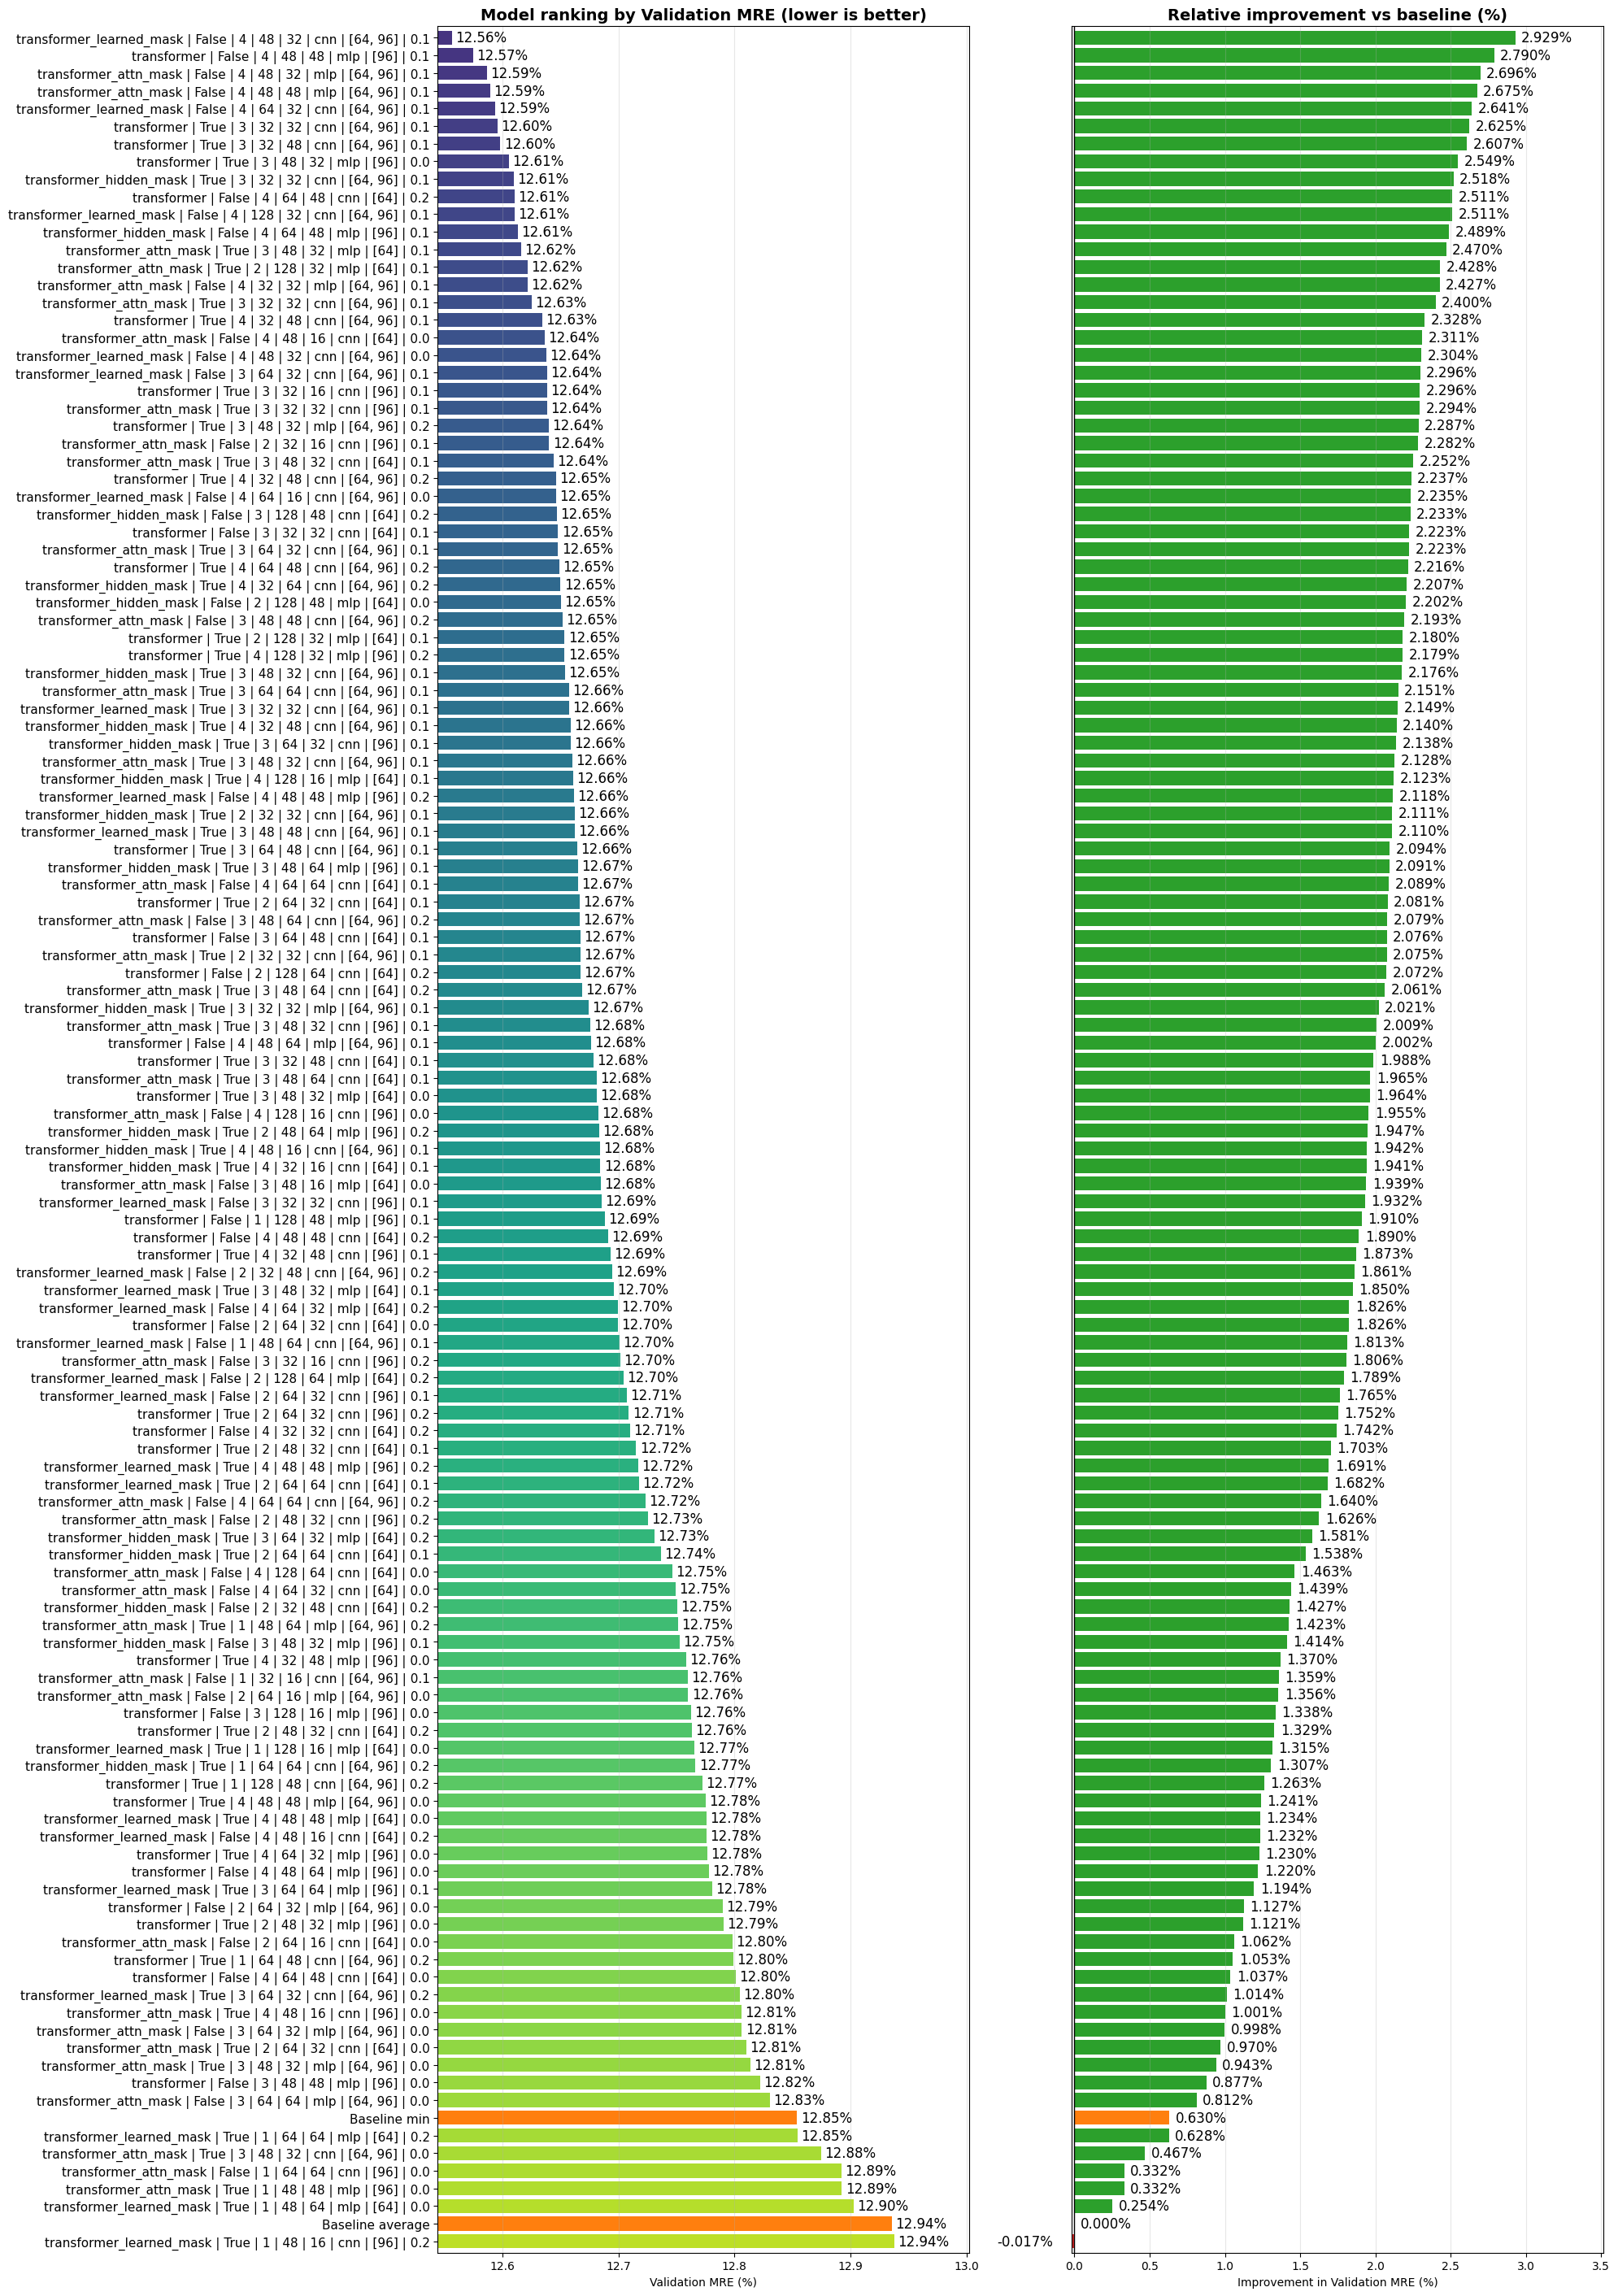

In [7]:
# Keep one row per hyperparameter configuration: if duplicates exist, keep the best one.
df_plot = type_df.copy()

# Convert list-valued columns to strings so labels stay readable and hashable
hyperparam_cols = [c for c in df_plot.columns if c != "val-mre"]
for col in hyperparam_cols:
    df_plot[col] = df_plot[col].apply(lambda x: str(x) if isinstance(x, list) else x)

# Collapse duplicated configurations and keep the one with the lowest validation MRE
df_plot = (
    df_plot
    .sort_values("val-mre", ascending=True)
    .drop_duplicates(subset=hyperparam_cols, keep="first")
    .reset_index(drop=True)
)

# Build a row-wise label for every configuration
df_plot["label"] = df_plot[hyperparam_cols].astype(str).agg(" | ".join, axis=1)

# Add baseline rows
df_plot = pd.concat([
    df_plot,
    pd.DataFrame([{
        "label": "Baseline average",
        "val-mre": average_test_mre_baseline
    }]),
    pd.DataFrame([{
        "label": "Baseline min",
        "val-mre": min_test_mre
    }])
], ignore_index=True)

# Metrics
df_plot["val-mre_%"] = 100 * df_plot["val-mre"]

baseline = df_plot.loc[
    df_plot["label"] == "Baseline average",
    "val-mre"
].iloc[0]

df_plot["improvement_vs_T0_%"] = (
    100 * (baseline - df_plot["val-mre"]) / baseline
)

# Sort every configuration, including baselines, by performance
df_plot = df_plot.sort_values("val-mre").reset_index(drop=True)

# Figure
n = len(df_plot)
fig, axes = plt.subplots(1, 2, figsize=(20, max(8, n * 0.225)))

# --- Left plot: Test MRE ---
colors = list(plt.cm.viridis(np.linspace(0.15, 0.9, n)))
colors[df_plot.index[df_plot["label"] == "Baseline average"][0]] = "tab:orange"
colors[df_plot.index[df_plot["label"] == "Baseline min"][0]] = "tab:orange"

axes[0].barh(df_plot["label"], df_plot["val-mre_%"], color=colors)
axes[0].margins(y=0.002)

axes[0].invert_yaxis()

axes[0].set(
    xlabel="Validation MRE (%)",
    xlim=(
        df_plot["val-mre_%"].min() * 0.999,
        df_plot["val-mre_%"].max() * 1.005
    )
)
# Setting the title with bold weight and a larger font size (e.g., 14)
axes[0].set_title(
    "Model ranking by Validation MRE (lower is better)", 
    fontweight="bold", 
    fontsize=14
)

axes[0].grid(axis="x", alpha=0.3)

# --- CHANGED: Increased labelsize from 9 to 11 for better readability ---
axes[0].tick_params(axis="y", labelsize=11)

for i, v in enumerate(df_plot["val-mre_%"]):
    axes[0].text(v + 0.003, i, f"{v:.2f}%", va="center", fontsize=12)

# --- Right plot: Improvement ---
imp_colors = [
    "tab:orange" if lbl == "Baseline min"
    else "tab:blue" if "Normal_training" in lbl
    else "tab:green" if x >= 0
    else "tab:red"
    for lbl, x in zip(df_plot["label"], df_plot["improvement_vs_T0_%"])
]

axes[1].barh(df_plot["label"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].margins(y=0.002)

axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)

axes[1].set(
    title="Relative improvement vs baseline",
    xlabel="Improvement in Validation MRE (%)",
    xlim=(
        df_plot["improvement_vs_T0_%"].min(),
        df_plot["improvement_vs_T0_%"].max() * 1.2
    )
)

axes[1].set_title(
    "Relative improvement vs baseline (%)",
    fontweight="bold", 
    fontsize=14
)

axes[1].grid(axis="x", alpha=0.3)
axes[1].set_yticklabels([])
axes[1].tick_params(axis="y", left=False)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(
        v + (0.04 if v >= 0 else -0.5),
        i,
        f"{v:.3f}%",
        va="center",
        fontsize=12
    )

plt.tight_layout()
plt.savefig("hyperparams_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

font_size usato: 8.3 pt  |  larghezza: 10.00 in


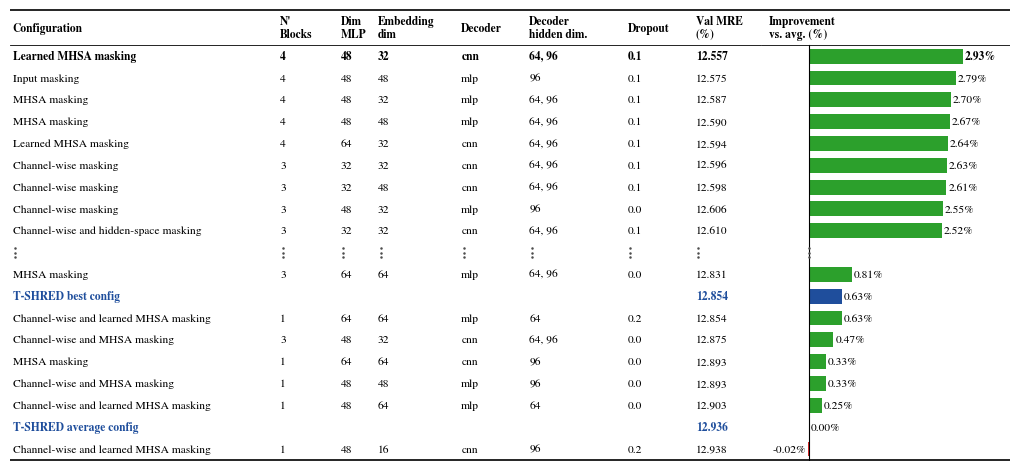

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------------
# Mapping / formattazione
# ----------------------------------------------------------------------------
ENCODER_MAP = {
    "transformer": "masking",
    "transformer_attn_mask": "MHSA masking",
    "transformer_learned_mask": "learned MHSA masking",
    "transformer_hidden_mask": "hidden-space masking",
}
# Intestazioni su due righe: riducono molto la larghezza delle colonne.
COL_RENAME = {
    "encoder_depth": "N'\nBlocks",
    "dim_feedforward": "Dim\nMLP",
    "hidden_size": "Embedding\ndim",
    "decoder": "Decoder",
    "decoder_hidden_sizes": "Decoder\nhidden dim.",
    "dropout": "Dropout",
}
BASELINE_MAP = {
    "Baseline min": "T-SHRED best config",
    "Baseline average": "T-SHRED average config",
}
INT_COLS = {"encoder_depth", "dim_feedforward", "hidden_size"}

PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}


def fmt_value(col, v):
    if col in INT_COLS:
        try:
            return str(int(round(float(v))))
        except (TypeError, ValueError):
            return str(v)
    if col == "decoder_hidden_sizes":
        return str(v).strip().strip("[]()")
    if col == "dropout":
        try:
            return str(float(v))
        except (TypeError, ValueError):
            return str(v)
    return str(v)



def build_config(row, channel_prefix="Channel-wise and "):
    enc = row["encoder"]
    if not isinstance(enc, str):  # righe baseline (NaN)
        return row["label"]

    name = ENCODER_MAP.get(enc.strip(), enc.strip())
    double_channels = str(row["double_channels"]).strip() == "True"

    if double_channels:
        if name == "masking":
            # "Channel-wise and masking" -> "Channel-wise masking"
            prefix = channel_prefix
            if prefix.rstrip().endswith("and"):
                prefix = prefix.rstrip()[:-3].rstrip() + " "
            name = prefix + name
        else:
            name = channel_prefix + name
    elif name == "masking":
        # Caso senza channel-wise: "Masking" -> "Input masking"
        name = "Input masking"

    return name[0].upper() + name[1:]


def _vdots(ax, x, y, color="0.3", ms=1.8, gap=0.2):
    ax.plot([x] * 3, [y - gap, y, y + gap], linestyle="none", marker="o",
            markersize=ms, color=color, markeredgewidth=0, clip_on=False)


# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
def plot_results_table(df_plot, hyperparam_cols, n_top=10, n_bottom=10,
                       fname="hyperparams_table",
                       target_width_in=7.0,      # larghezza FINALE in pollici (7.0 ~ \textwidth a 2 colonne / 1 colonna larga)
                       font_size=None,           # None -> calcolato per riempire target_width_in
                       channel_prefix="Channel-wise and ",   # es. "CW + " per stringere ancora
                       bar_header="Improvement\nvs. avg. (%)",
                       bar_color="#2ca02c", neg_color="#d62728",
                       baseline_color="#1f4e9c",
                       char_k=0.0080,            # larghezza carattere (in) per pt di font
                       bar_k=0.30,               # larghezza colonna barre (in) per pt di font
                       col_pad=2.2,              # padding colonne (in unita' di carattere)
                       save_formats=("pdf", "png"), dpi=600, show=True):
    """
    Tabella + barre di miglioramento %. Il font viene scelto automaticamente
    in modo che la figura sia larga esattamente `target_width_in`: includila in
    LaTeX con width=\\textwidth (scala 1:1) e il font risultera' quello reale in pt.
    """
    df = df_plot.sort_values("val-mre").reset_index(drop=True).copy()

    if "encoder" in hyperparam_cols and "double_channels" in hyperparam_cols:
        df["Configuration"] = df.apply(lambda r: build_config(r, channel_prefix), axis=1)
        hyperparam_cols = ["Configuration"] + [
            c for c in hyperparam_cols if c not in ("encoder", "double_channels")
        ]

    recs = df.to_dict("records")
    rows = recs[:n_top] + [None] + recs[-n_bottom:] if len(recs) > n_top + n_bottom else recs
    m = len(rows)
    is_base = [r is not None and str(r["label"]).startswith("Baseline") for r in rows]

    headers = [COL_RENAME.get(c, c) for c in hyperparam_cols] + ["Val MRE\n(%)"]
    cells = []
    for r, b in zip(rows, is_base):
        if r is None:
            cells.append(None)
        elif b:
            cells.append([BASELINE_MAP.get(r["label"], r["label"])]
                         + [""] * (len(hyperparam_cols) - 1)
                         + [f"{r['val-mre_%']:.3f}"])
        else:
            cells.append([fmt_value(c, r[c]) for c in hyperparam_cols]
                         + [f"{r['val-mre_%']:.3f}"])

    # ---- larghezze colonne (in caratteri), intestazioni = riga piu' lunga ----
    widths = []
    for j, h in enumerate(headers):
        txt = [len(c[j]) for c, b in zip(cells, is_base)
               if c is not None and not (j == 0 and b)]
        h_len = max(len(line) for line in h.split("\n"))
        widths.append(max([h_len * 1.15] + [t * 1.03 for t in txt]) + col_pad)
    xs = np.cumsum([0] + widths)
    total = xs[-1]
    pad_x = 0.4
    lefts = xs[:-1] + pad_x

    # ---- font auto-fit: table_w + bar_w = target_width_in ----
    if font_size is None:
        font_size = target_width_in / (total * char_k + bar_k)
    char_in = char_k * font_size
    bar_width_in = bar_k * font_size
    table_w = total * char_in
    row_h = font_size * 1.85 / 72
    head_rows = 1.6                                   # altezza header (in righe)
    fig_h = row_h * (m + head_rows + 0.6)

    rc = dict(PAPER_RC, **{"font.size": font_size})
    with plt.rc_context(rc):
        fig, (ax_t, ax_b) = plt.subplots(
            1, 2, figsize=(table_w + bar_width_in, fig_h), sharey=True,
            gridspec_kw={"width_ratios": [table_w, bar_width_in], "wspace": 0.0},
        )
        y = np.arange(m)
        Y_MID = -0.5
        Y_TOP = Y_MID - head_rows
        Y_HEAD = (Y_TOP + Y_MID) / 2
        Y_BOT = m - 0.5
        RULE_THICK, RULE_THIN = 1.2, 0.6

        # ---- tabella ----
        ax_t.set_xlim(0, total)
        ax_t.set_ylim(Y_BOT + 0.05, Y_TOP - 0.05)
        ax_t.axis("off")
        for j, h in enumerate(headers):
            ax_t.text(lefts[j], Y_HEAD, h, ha="left", va="center",
                      fontweight="bold", linespacing=1.05)
        ax_t.axhline(Y_TOP, color="black", lw=RULE_THICK)
        ax_t.axhline(Y_MID, color="black", lw=RULE_THIN)
        ax_t.axhline(Y_BOT, color="black", lw=RULE_THICK)

        for i, (r, c, b) in enumerate(zip(rows, cells, is_base)):
            if r is None:
                for j in range(len(headers)):
                    _vdots(ax_t, lefts[j] + 0.4, i)
                continue
            for j, t in enumerate(c):
                ax_t.text(lefts[j], i, t, ha="left", va="center",
                          fontweight="bold" if (i == 0 or b) else "normal",
                          color=baseline_color if b else "black")

        # ---- barre ----
        vals = np.array([np.nan if r is None else r["improvement_vs_T0_%"] for r in rows])
        vmax, vmin = np.nanmax(vals), min(0.0, np.nanmin(vals))
        span = vmax - vmin
        xmin = vmin - (0.30 * span if vmin < 0 else 0.02 * span)
        xmax = vmax + 0.30 * span
        ax_b.set_xlim(xmin, xmax)

        colors = [("none" if r is None else baseline_color if b
                   else bar_color if v >= 0 else neg_color)
                  for r, b, v in zip(rows, is_base, vals)]
        ax_b.barh(y, np.nan_to_num(vals, nan=0.0), color=colors, height=0.68)
        ax_b.plot([0, 0], [Y_MID, Y_BOT], color="black", lw=0.8)

        ax_b.text(0.03, Y_HEAD, bar_header, transform=ax_b.get_yaxis_transform(),
                  ha="left", va="center", fontweight="bold", linespacing=1.05)
        ax_b.axhline(Y_TOP, color="black", lw=RULE_THICK)
        ax_b.axhline(Y_MID, color="black", lw=RULE_THIN)
        ax_b.axhline(Y_BOT, color="black", lw=RULE_THICK)

        for i, (r, v) in enumerate(zip(rows, vals)):
            if r is None:
                _vdots(ax_b, 0, i)
                continue
            ax_b.text(v + (0.012 if v >= 0 else -0.012) * span, i, f"{v:.2f}%",
                      ha="left" if v >= 0 else "right", va="center",
                      fontweight="bold" if i == 0 else "normal")

        for s in ax_b.spines.values():
            s.set_visible(False)
        ax_b.set_xticks([])
        ax_b.set_yticks([])

        fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
        for ext in save_formats:
            fig.savefig(f"{fname}.{ext}", dpi=dpi, bbox_inches="tight", pad_inches=0.03)
        print(f"font_size usato: {font_size:.1f} pt  |  larghezza: {table_w + bar_width_in:.2f} in")
        if show:
            plt.show()
        plt.close(fig)


# --- USO ---
plot_results_table(df_plot, hyperparam_cols, n_top=9, n_bottom=9,
                   fname="HYDRO_7_tuning", target_width_in=10.0)
# LaTeX: \includegraphics[width=\textwidth]{HYDRO_tuning.pdf}

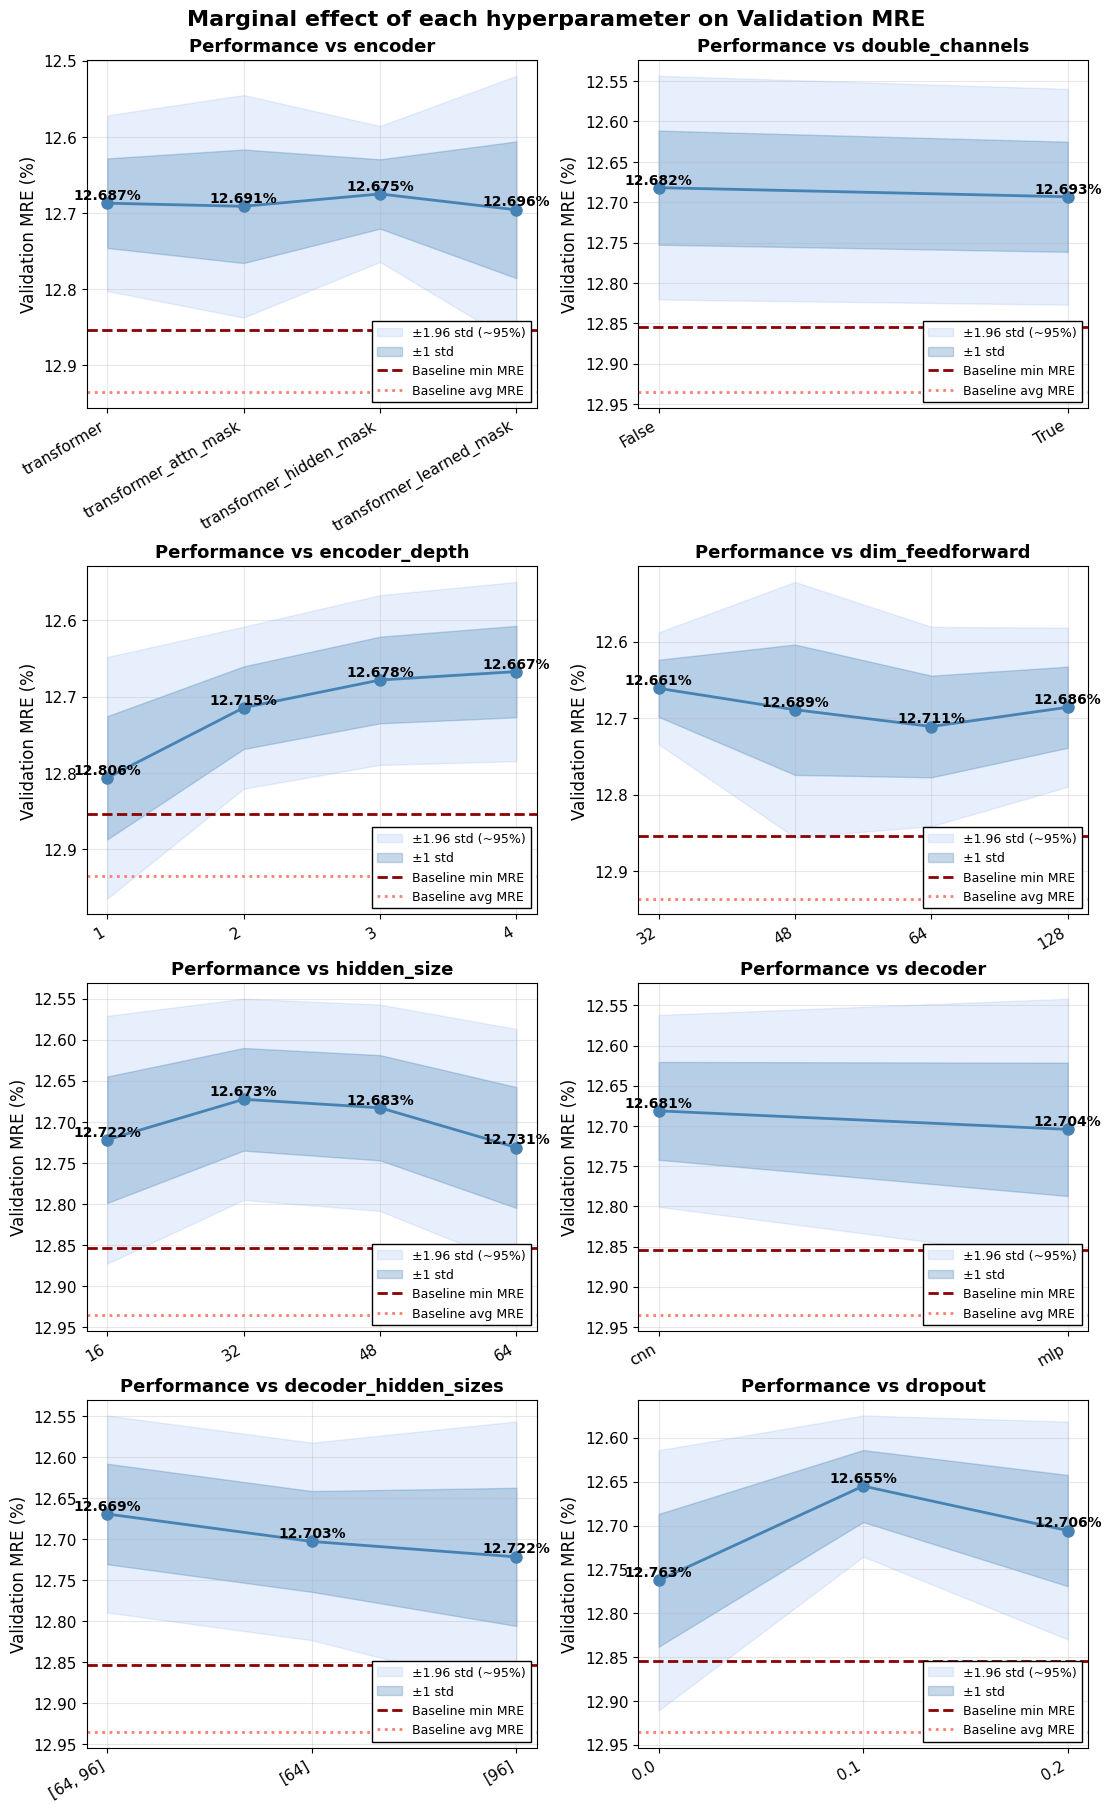

In [9]:
n_rows = 4
n_cols = int(np.ceil(len(hyperparam_cols) / n_rows))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(5.5 * n_cols, 4.5 * n_rows),
    constrained_layout=True
)

axes = axes.flatten()

# Convert list-valued hyperparameters to strings so groupby can hash them safely.
type_df_plot = type_df.copy()
for col in hyperparam_cols:
    if type_df_plot[col].apply(lambda x: isinstance(x, list)).any():
        type_df_plot[col] = type_df_plot[col].apply(lambda x: str(x) if isinstance(x, list) else x)

# Baselines in %
baseline_min_pct = min_test_mre * 100
baseline_avg_pct = average_test_mre_baseline * 100

for idx, col in enumerate(hyperparam_cols):

    ax = axes[idx]

    perf = (
        type_df_plot
        .groupby(col)["val-mre"]
        .agg(["mean", "std"])
        .reset_index()
        .sort_values(col)
    )

    x_vals = np.arange(len(perf))

    mean_pct = perf["mean"] * 100
    std_pct  = perf["std"]  * 100
    ci95_pct = 1.96 * std_pct

    # Main curve
    ax.plot(
        x_vals,
        mean_pct,
        marker="o",
        linewidth=2,
        markersize=8,
        color="steelblue"
    )

    # ±1.96 std band (~95%)
    ax.fill_between(
        x_vals,
        mean_pct - ci95_pct,
        mean_pct + ci95_pct,
        alpha=0.15,
        color="cornflowerblue",
        label="±1.96 std (~95%)"
    )

    # ±1 std band
    ax.fill_between(
        x_vals,
        mean_pct - std_pct,
        mean_pct + std_pct,
        alpha=0.30,
        color="steelblue",
        label="±1 std"
    )

    # Baseline min MRE
    ax.axhline(
        baseline_min_pct,
        color="darkred",
        linestyle="--",
        linewidth=2,
        label="Baseline min MRE"
    )

    # Baseline average MRE
    ax.axhline(
        baseline_avg_pct,
        color="salmon",
        linestyle=":",
        linewidth=2,
        label="Baseline avg MRE"
    )

    ax.set_xticks(x_vals)

    ax.set_xticklabels(
        perf[col].astype(str),
        rotation=30,
        ha="right",
        fontsize=11
    )

    ax.set_ylabel("Validation MRE (%)", fontsize=12)

    ax.set_title(
        f"Performance vs {col}",
        fontsize=13,
        fontweight="bold"
    )

    ax.tick_params(axis="y", labelsize=11)

    ax.grid(alpha=0.3)

    # Lower is better
    ax.invert_yaxis()

    ax.legend(
        fontsize=9,
        loc="lower right",
        frameon=True,
        fancybox=False,
        framealpha=1,
        facecolor="white",
        edgecolor="black"
    )

    # Annotate points
    y_offset = ci95_pct.max() * 0.03 if ci95_pct.max() > 0 else 0.02

    for x, (_, row) in zip(x_vals, perf.iterrows()):

        ax.text(
            x,
            row["mean"] * 100 - y_offset,
            f"{row['mean'] * 100:.3f}%",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

# Hide unused axes
for idx in range(len(hyperparam_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle(
    "Marginal effect of each hyperparameter on Validation MRE",
    fontsize=16,
    fontweight="bold"
)

plt.savefig(
    "hyperparam_marginal_effects.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

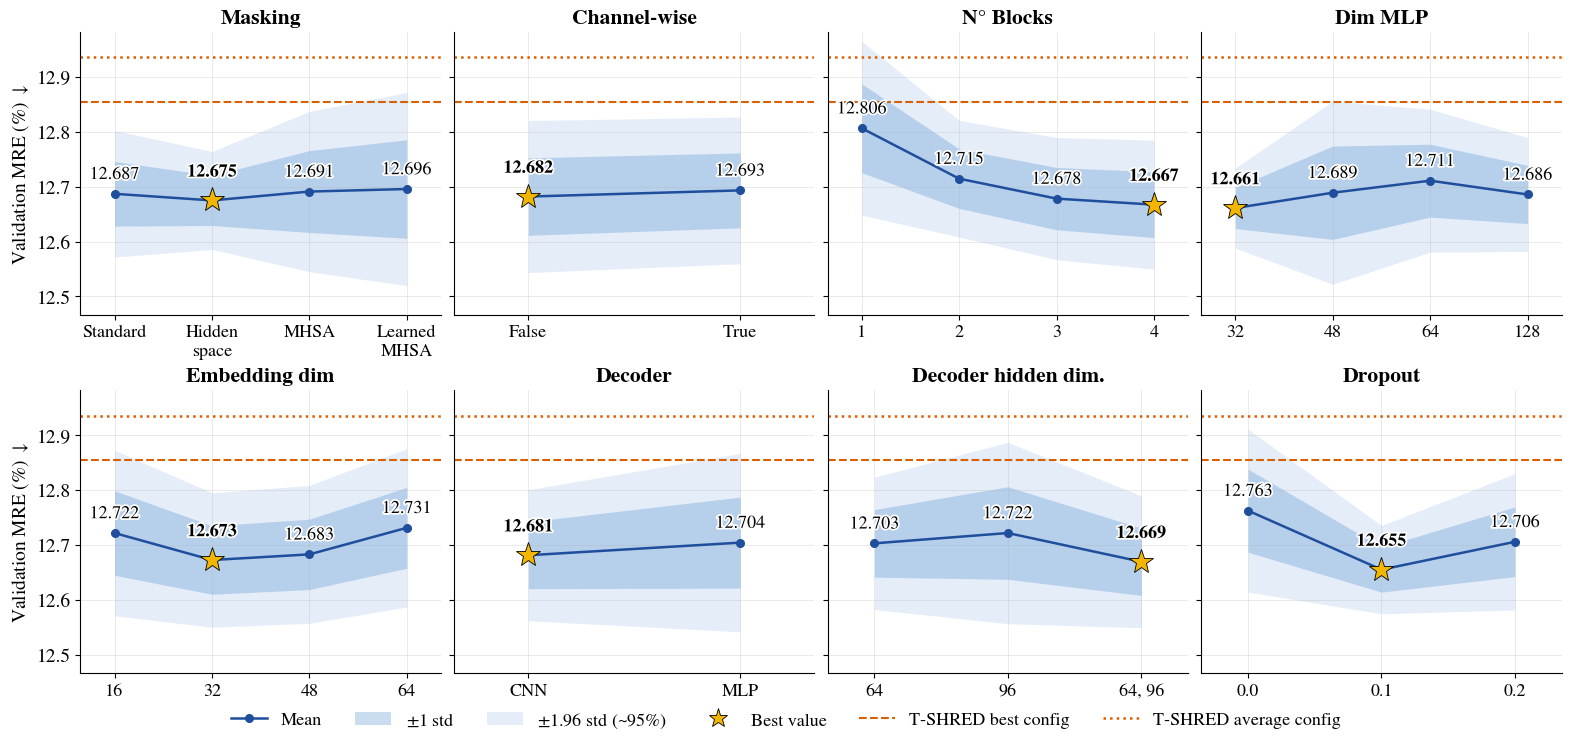

In [10]:
import re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ----------------------------------------------------------------------------
# Mapping / formattazione (coerente con la tabella)
# ----------------------------------------------------------------------------
TITLE_MAP = {
    "encoder": "Masking",
    "double_channels": "Channel-wise",
    "encoder_depth": "N° Blocks",
    "dim_feedforward": "Dim MLP",
    "hidden_size": "Embedding dim",
    "decoder": "Decoder",
    "decoder_hidden_sizes": "Decoder hidden dim.",
    "dropout": "Dropout",
}
ENCODER_MAP = {
    "transformer": "Standard",
    "transformer_attn_mask": "MHSA",
    "transformer_learned_mask": "Learned\nMHSA",
    "transformer_hidden_mask": "Hidden\nspace",
}
ENCODER_ORDER = [                      # ordine di visualizzazione nel primo pannello
    "transformer",
    "transformer_hidden_mask",
    "transformer_attn_mask",
    "transformer_learned_mask",
]
INT_COLS = {"encoder_depth", "dim_feedforward", "hidden_size"}

PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}


def _tick_label(col, v):
    if col == "encoder":
        return ENCODER_MAP.get(str(v), str(v))
    if col in INT_COLS:
        try:
            return str(int(round(float(v))))
        except (TypeError, ValueError):
            return str(v)
    if col == "decoder_hidden_sizes":
        return str(v).strip().strip("[]()")
    if col == "dropout":
        try:
            return str(float(v))
        except (TypeError, ValueError):
            return str(v)
    if col == "decoder":
        return str(v).upper()
    return str(v)


# ----------------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------------
def plot_marginal_effects(type_df, hyperparam_cols,
                          baseline_min_pct, baseline_avg_pct,
                          n_cols=4, font_size=13,
                          panel_size=(3.9, 3.4),
                          fname="hyperparam_marginal_effects",
                          band_color="#4c8bd0", line_color="#1f4e9c",
                          baseline_color="#d95f02", best_color="#f2b600",
                          annotate=True, value_fontsize=None, suptitle=None,
                          save_formats=("pdf", "png"), dpi=600, show=True):
    """
    Effetto marginale di ogni iperparametro sulla Val MRE (media ± std).
    Pannelli su n_cols colonne (default 4 -> 2 righe per 8 iperparametri),
    asse y condiviso, legenda unica in fondo.
    """
    rc = dict(PAPER_RC, **{"font.size": font_size})
    with plt.rc_context(rc):
        n_plots = len(hyperparam_cols)
        n_rows = int(np.ceil(n_plots / n_cols))

        fig, axes = plt.subplots(
            n_rows, n_cols, sharey=True, constrained_layout=True,
            figsize=(panel_size[0] * n_cols, panel_size[1] * n_rows + 0.6),
        )
        axes = np.atleast_1d(axes).flatten()

        # liste -> stringhe, per poter fare groupby
        df = type_df.copy()
        for col in hyperparam_cols:
            if df[col].apply(lambda x: isinstance(x, list)).any():
                df[col] = df[col].apply(lambda x: str(x) if isinstance(x, list) else x)

        # statistiche per ogni iperparametro (in %)
        stats = {}
        lo, hi = baseline_min_pct, baseline_avg_pct
        for col in hyperparam_cols:
            perf = df.groupby(col)["val-mre"].agg(["mean", "std"]).reset_index()
            if col == "encoder":
                order = [ENCODER_ORDER.index(v) if v in ENCODER_ORDER else 99
                         for v in perf[col]]
                perf = perf.iloc[np.argsort(order, kind="stable")]
            elif col == "decoder_hidden_sizes":
                # prima le liste corte, poi quelle lunghe: [64], [96], [64, 96]
                def _key(v):
                    nums = [int(n) for n in re.findall(r"\d+", str(v))]
                    return (len(nums), nums)
                perf = perf.iloc[sorted(range(len(perf)), key=lambda i: _key(perf[col].iloc[i]))]
            else:
                perf = perf.sort_values(col)
            perf = perf.reset_index(drop=True)
            perf["mean"] *= 100
            perf["std"] = perf["std"].fillna(0) * 100
            stats[col] = perf
            lo = min(lo, (perf["mean"] - 1.96 * perf["std"]).min())
            hi = max(hi, (perf["mean"] + 1.96 * perf["std"]).max())
        span = hi - lo
        ylim = (lo - 0.12 * span, hi + 0.04 * span)        # asse normale: meglio = più in basso (↓)

        for idx, col in enumerate(hyperparam_cols):
            ax = axes[idx]
            perf = stats[col]
            x = np.arange(len(perf))
            mean, std = perf["mean"].values, perf["std"].values

            ax.fill_between(x, mean - 1.96 * std, mean + 1.96 * std,
                            color=band_color, alpha=0.15, linewidth=0)
            ax.fill_between(x, mean - std, mean + std,
                            color=band_color, alpha=0.30, linewidth=0)
            ax.plot(x, mean, marker="o", lw=1.8, ms=5.5, color=line_color)

            ax.axhline(baseline_min_pct, color=baseline_color, ls="--", lw=1.5)
            ax.axhline(baseline_avg_pct, color=baseline_color, ls=":", lw=1.8)

            labels = [_tick_label(col, v) for v in perf[col]]
            ax.set_xticks(x)
            ax.set_xticklabels(labels, rotation=0, ha="center")
            ax.set_xlim(-0.35, len(perf) - 1 + 0.35)
            ax.set_title(TITLE_MAP.get(col, col), fontweight="bold")

            # stella sul valore migliore (MRE minima) + valore numerico
            ib = int(np.argmin(mean))
            ax.plot(x[ib], mean[ib], marker="*", ms=font_size * 1.4, ls="none",
                    color=best_color, mec="black", mew=0.6, zorder=5)
            if annotate:
                # valore su ogni punto, sopra al marker; sopra la stella per il migliore (offset in punti)
                for k, (xk, mk) in enumerate(zip(x, mean)):
                    best = (k == ib)
                    ax.annotate(f"{mk:.3f}", (xk, mk),
                                xytext=(0, font_size * (1.1 if best else 0.6)),
                                textcoords="offset points", ha="center", va="bottom",
                                fontsize=value_fontsize or font_size,
                                fontweight="bold" if best else "normal", zorder=6,
                                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

            ax.grid(alpha=0.3, lw=0.6)
            for s in ("top", "right"):
                ax.spines[s].set_visible(False)

        axes[0].set_ylim(*ylim)                              # sharey: vale per tutti
        for r in range(n_rows):
            axes[r * n_cols].set_ylabel(r"Validation MRE (%) $\downarrow$",
                                        fontsize=font_size + 1)
        for ax in axes[:n_plots]:
            ax.tick_params(axis="y", labelsize=font_size + 1)    # numeri asse y più grandi
            ax.tick_params(axis="x", labelsize=font_size)
        for ax in axes[n_plots:]:
            ax.set_visible(False)

        # ---- legenda unica in fondo ----
        handles = [
            Line2D([0], [0], color=line_color, marker="o", lw=1.8, ms=5.5, label="Mean"),
            Patch(facecolor=band_color, alpha=0.30, label=r"$\pm$1 std"),
            Patch(facecolor=band_color, alpha=0.15, label=r"$\pm$1.96 std (~95%)"),
            Line2D([0], [0], color="none", marker="*", ms=font_size * 1.1, mfc=best_color,
                   mec="black", mew=0.6, label="Best value"),
            Line2D([0], [0], color=baseline_color, ls="--", lw=1.5, label="T-SHRED best config"),
            Line2D([0], [0], color=baseline_color, ls=":", lw=1.8, label="T-SHRED average config"),
        ]
        fig.legend(handles=handles, loc="outside lower center",
                   ncol=len(handles), frameon=False, fontsize=font_size,
                   handlelength=2.0, columnspacing=1.8)

        if suptitle:
            fig.suptitle(suptitle, fontweight="bold", fontsize=font_size + 3)

        for ext in save_formats:
            fig.savefig(f"{fname}.{ext}", dpi=dpi, bbox_inches="tight", pad_inches=0.03)
        if show:
            plt.show()
        del fig


# --- USO ---
baseline_min_pct = min_test_mre * 100
baseline_avg_pct = average_test_mre_baseline * 100
plot_marginal_effects(type_df, hyperparam_cols, baseline_min_pct, baseline_avg_pct,
                      n_cols=4, font_size=13, fname="HYDRO_8_tnuning_meff")